# Домашнее задание 4

Работа сдается на портале VK Education

В каждом задании оставьте код, результат его выполнения и ответ на вопрос задания.

**Перед сдачей**

Перезапустите kernel и выполните все ячейки сверху вниз. Проверьте, что таблицы и графики подписаны, а выводы содержат конкретные значения

Реализованы метрики, KNN и SGD для двух функций потерь. Данные создаются внутри
ноутбука; загружать CSV не требуется. Все случайные эксперименты воспроизводимы.

**Уточнения к шаблону.** Для MSE используется градиент с множителем 2.
Регуляризация строго соответствует условию: $R(w)/C=\|w\|_2^2/C$,
свободный коэффициент не штрафуется. `fit` возвращает модель, а история хранится
в её атрибутах. В режиме `lin_reg` метод `predict` возвращает непрерывный ответ,
в режиме `log_reg` — класс. Посторонняя функция про постоянную Капрекара исключена.

In [1]:
import platform
from functools import partial
from timeit import repeat

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from scipy.spatial.distance import cdist
from scipy.optimize import minimize
from sklearn import datasets
from sklearn.base import BaseEstimator
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, mean_squared_error, r2_score)
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits

# Один поток уменьшает накладные расходы на небольших матрицах.
# Для обоих KNN ограничения одинаковы.
thread_controller = threadpool_limits(limits=1)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.25, 'font.size': 11})
pd.set_option('display.precision', 6)
print(f'Python {platform.python_version()}, NumPy {np.__version__}, '
      f'SciPy {scipy.__version__}, sklearn {sklearn.__version__}')

Python 3.12.14, NumPy 2.3.5, SciPy 1.17.0, sklearn 1.8.0


## Метрики (1 балл)

Необходимо реализовать метрики качества и сравнить их c реализацией sklearn

$accuracy  = \dfrac{TP + TN}{TP + TN + FP + FN}$

$precision  = \dfrac{TP}{TP + FP}$

$recall  = \dfrac{TP}{TP + FN}$


$F1 = 2 \cdot \dfrac{\mathrm{Precision} \cdot \mathrm{Recall}}
{\mathrm{Precision} + \mathrm{Recall}}$


**Roc-Auc** - равен доле пар объектов вида (объект класса 1, объект класса 0), которые алгоритм верно упорядочил (скор класса 1 будет выше скора класса 0)

- ROC-кривая (Receiver Operating Characteristic) строится путем отображения зависимости TPR (True Positive Rate — доля истинно положительных срабатываний) от FPR (False Positive Rate — доля ложноположительных срабатываний) при всех возможных порогах классификации.

- AUC (area under curve)— это числовое значение (площадь), находящееся под этой кривой. Оно всегда лежит в диапазоне от 0.0 до 1.0.

[Один из алгоритмов подсчета](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/)

In [2]:
def _paired_arrays(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if (y_true.ndim != 1 or y_pred.shape != y_true.shape
            or y_true.size == 0):
        raise ValueError('Нужны непустые одномерные массивы одинаковой длины.')
    return y_true, y_pred


def _binary_counts(y_true, y_pred):
    y_true, y_pred = _paired_arrays(y_true, y_pred)
    if not (np.isin(y_true, [0, 1]).all() and np.isin(y_pred, [0, 1]).all()):
        raise ValueError('Ожидаются бинарные метки 0 и 1.')
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fp, fn


def my_accuracy_score(y_true, y_pred):
    y_true, y_pred = _paired_arrays(y_true, y_pred)
    return float(np.mean(y_true == y_pred))


def my_recall_score(y_true, y_pred):
    tp, fp, fn = _binary_counts(y_true, y_pred)
    return float(tp / (tp + fn)) if tp + fn else 0.0


def my_precision_score(y_true, y_pred):
    tp, fp, fn = _binary_counts(y_true, y_pred)
    return float(tp / (tp + fp)) if tp + fp else 0.0


def my_f1_score(y_true, y_pred):
    tp, fp, fn = _binary_counts(y_true, y_pred)
    return float(2 * tp / (2 * tp + fp + fn)) if 2 * tp + fp + fn else 0.0


def my_roc_auc_score(y_true, y_pred):
    # y_pred — вещественные оценки класса 1, НЕ бинарные предсказания.
    y_true, scores = _paired_arrays(y_true, y_pred)
    if not np.isin(y_true, [0, 1]).all() or not np.isfinite(scores).all():
        raise ValueError('Нужны метки 0/1 и конечные оценки.')
    n_pos = np.sum(y_true == 1)
    n_neg = len(y_true) - n_pos
    if n_pos == 0 or n_neg == 0:
        raise ValueError('ROC-AUC определена только при наличии обоих классов.')

    # Ранговая формула Манна — Уитни, O(n log n).
    # Совпавшие оценки получают средний ранг: такая пара даёт вклад 0.5.
    order = np.argsort(scores, kind='stable')
    sorted_scores = scores[order]
    starts = np.r_[0, np.flatnonzero(np.diff(sorted_scores)) + 1]
    ends = np.r_[starts[1:], len(scores)]
    average_ranks = (starts + 1 + ends) / 2
    sorted_ranks = np.repeat(average_ranks, ends - starts)
    positive_rank_sum = sorted_ranks[y_true[order] == 1].sum()
    return float((positive_rank_sum - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metric_comparison(y_true, y_pred, scores):
    rows = [
        ('accuracy', my_accuracy_score(y_true, y_pred), accuracy_score(y_true, y_pred)),
        ('recall', my_recall_score(y_true, y_pred), recall_score(y_true, y_pred, zero_division=0)),
        ('precision', my_precision_score(y_true, y_pred), precision_score(y_true, y_pred, zero_division=0)),
        ('F1', my_f1_score(y_true, y_pred), f1_score(y_true, y_pred, zero_division=0)),
        ('ROC-AUC', my_roc_auc_score(y_true, scores), roc_auc_score(y_true, scores)),
    ]
    result = pd.DataFrame(rows, columns=['Метрика', 'Своя реализация', 'sklearn']).set_index('Метрика')
    result['Разница'] = np.abs(result['Своя реализация'] - result['sklearn'])
    np.testing.assert_allclose(result['Своя реализация'], result['sklearn'], atol=1e-12)
    return result

In [3]:
y_true = np.array([0, 1, 0, 1, 0, 1, 1, 1])
y_predict = np.array([0, 1, 1, 1, 0, 1, 0, 0])
y_predict_proba = np.array([0.1, 0.7, 0.6, 0.9, 0.1, 0.2, 0.75, 0.5])
assert len(y_true) == len(y_predict)

In [4]:
metrics_example = metric_comparison(y_true, y_predict, y_predict_proba)
display(metrics_example)

# Проверяем совпавшие оценки и вырожденные предсказания.
rng = np.random.default_rng(42)
for _ in range(30):
    labels = np.r_[0, 1, rng.integers(0, 2, 98)]
    scores = np.round(rng.random(100), 1)
    metric_comparison(labels, (scores >= 0.5).astype(int), scores)
for labels in [np.zeros(5, dtype=int), np.ones(5, dtype=int)]:
    for pred in [np.zeros(5, dtype=int), np.ones(5, dtype=int)]:
        assert my_precision_score(labels, pred) == precision_score(labels, pred, zero_division=0)
        assert my_recall_score(labels, pred) == recall_score(labels, pred, zero_division=0)
        assert my_f1_score(labels, pred) == f1_score(labels, pred, zero_division=0)
assert my_roc_auc_score([0, 1], [0.5, 0.5]) == 0.5
assert my_accuracy_score([0, 1, 2], [0, 2, 2]) == 2 / 3
print('Все пять метрик совпадают со sklearn; проверки равных скоров и нулевых знаменателей пройдены.')

,Своя реализация,sklearn,Разница
Метрика,,,
accuracy,0.625000,0.625000,0.0
recall,0.600000,0.600000,0.0
precision,0.750000,0.750000,0.0
F1,0.666667,0.666667,0.0
ROC-AUC,0.866667,0.866667,0.0


Все пять метрик совпадают со sklearn; проверки равных скоров и нулевых знаменателей пройдены.


**Вывод.** При нулевом знаменателе precision/recall/F1 возвращают 0
(соглашение `zero_division=0`). ROC-AUC использует вероятности/скоры и учитывает
равенство скоров с весом 0.5. На примере accuracy = 0.625, precision = 0.75,
recall = 0.6, F1 = 0.666667, ROC-AUC = 0.866667.

## KNN (4 балла)

**Задание 1 (2 балла)**

Реализовать KNN в классе MyKNeighborsClassifier (обязательное условие: точность не ниже sklearn реализации)
Разберитесь самостоятельно, какая мера расстояния используется в [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) дефолтно и реализуйте свой алгоритм именно с этой мерой.
Для подсчета расстояний можно использовать функции [отсюда](https://docs.scipy.org/doc/scipy/reference/spatial.distance.html). Можно пользоваться [pairwise_distances](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise_distances.html)

По умолчанию `KNeighborsClassifier` использует метрику Минковского с `p=2`,
то есть евклидово расстояние, и равные веса соседей (`weights='uniform'`).
Вычисляем квадраты евклидовых расстояний: извлечение корня не меняет порядок.
Затем выбираем k ближайших объектов и голосуем. При равенстве голосов выбирается
минимальная метка класса; при равенстве расстояний — более ранний объект обучения.

In [5]:
class MyKNeighborsClassifier(BaseEstimator):
    def __init__(self, n_neighbors, algorithm='brute'):
        self.n_neighbors = n_neighbors
        self.algorithm = algorithm

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError('Некорректные размеры X и y.')
        if not np.isfinite(X).all():
            raise ValueError('X должна содержать конечные числа.')
        if self.algorithm != 'brute':
            raise ValueError("Реализован algorithm='brute'.")
        if not isinstance(self.n_neighbors, (int, np.integer)) or not 1 <= self.n_neighbors <= len(X):
            raise ValueError('n_neighbors должно быть целым от 1 до числа объектов.')
        self.X_train_ = np.ascontiguousarray(X).copy()
        self.classes_, self.y_encoded_ = np.unique(y, return_inverse=True)
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        check_is_fitted(self, 'X_train_')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError('Неверная форма или значения X.')
        distances = cdist(X, self.X_train_, metric='sqeuclidean')
        nearest = np.argsort(distances, axis=1, kind='stable')[:, :self.n_neighbors]
        labels = self.y_encoded_[nearest]
        votes = (labels[:, :, None] == np.arange(len(self.classes_))).sum(axis=1)
        return self.classes_[np.argmax(votes, axis=1)]

**IRIS**

В библиотеке scikit-learn есть несколько датасетов из коробки. Один из них [Ирисы Фишера](https://ru.wikipedia.org/wiki/%D0%98%D1%80%D0%B8%D1%81%D1%8B_%D0%A4%D0%B8%D1%88%D0%B5%D1%80%D0%B0)

In [6]:
iris = datasets.load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.1, stratify=iris.target, random_state=42)
clf = KNeighborsClassifier(n_neighbors=2, algorithm='brute')
my_clf = MyKNeighborsClassifier(n_neighbors=2, algorithm='brute')
clf.fit(X_train, y_train)
my_clf.fit(X_train, y_train)
sklearn_pred, my_clf_pred = clf.predict(X_test), my_clf.predict(X_test)
knn_results = pd.DataFrame({
    'Модель': ['sklearn KNN', 'MyKNeighborsClassifier'],
    'Accuracy': [accuracy_score(y_test, sklearn_pred), accuracy_score(y_test, my_clf_pred)]})
display(knn_results)
print('Фактическая метрика sklearn:', clf.effective_metric_)
assert accuracy_score(y_test, my_clf_pred) >= accuracy_score(y_test, sklearn_pred)
np.testing.assert_array_equal(my_clf_pred, sklearn_pred)
print('Предсказания совпали на всех', len(y_test), 'тестовых объектах.')

# Независимая проверка на случайных данных без равных расстояний.
knn_rng = np.random.default_rng(7)
X_check, X_query = knn_rng.normal(size=(80, 4)), knn_rng.normal(size=(20, 4))
y_check = knn_rng.choice(['a', 'b', 'c'], size=80)
for k in [1, 2, 5, 80]:
    a = MyKNeighborsClassifier(k).fit(X_check, y_check)
    b = KNeighborsClassifier(k, algorithm='brute').fit(X_check, y_check)
    np.testing.assert_array_equal(a.predict(X_query), b.predict(X_query))
print('Проверки разных k и строковых меток пройдены.')

,Модель,Accuracy
0,sklearn KNN,0.933333
1,MyKNeighborsClassifier,0.933333


Фактическая метрика sklearn: euclidean
Предсказания совпали на всех 15 тестовых объектах.
Проверки разных k и строковых меток пройдены.


**Задание 2 (2 балла)**

Давайте попробуем добиться скорости работы на fit, predict сравнимой со sklearn для iris. Допускается замедление не более чем в 2 раза.
Для этого используем numpy.

In [7]:
def median_time_ms(function, number=200, repeats=7):
    function()  # прогрев
    return 1000 * np.median(repeat(function, number=number, repeat=repeats)) / number


timings = []
for name, reference, custom in [
    ('fit', lambda: clf.fit(X_train, y_train), lambda: my_clf.fit(X_train, y_train)),
    ('predict', lambda: clf.predict(X_test), lambda: my_clf.predict(X_test)),
]:
    t_ref = median_time_ms(reference)
    t_custom = median_time_ms(custom)
    timings.append((name, t_ref, t_custom, t_custom / t_ref))
timing_table = pd.DataFrame(timings, columns=[
    'Операция', 'sklearn, мс', 'Своя, мс', 'Своя / sklearn']).set_index('Операция')
display(timing_table)
assert (timing_table['Своя / sklearn'] <= 2).all(), 'На этой машине превышен порог замедления.'
display(Markdown(
    '**Вывод.** Для fit отношение времени своей реализации к sklearn равно '
    f"{timing_table.loc['fit', 'Своя / sklearn']:.3f}, для predict — "
    f"{timing_table.loc['predict', 'Своя / sklearn']:.3f}. "
    'Оба значения не превышают 2. Использованы медианы 7 серий по 200 вызовов. '
    'Измерение относится к Iris и текущей среде: на больших данных результат может отличаться. '
    'Обучение только сохраняет данные; расстояния, сортировка и голосование выполняются '
    'массивными операциями. Полная сортировка проста и быстра для Iris, но на больших '
    'выборках требует больше работы, чем частичный выбор соседей.'))

,"sklearn, мс","Своя, мс",Своя / sklearn
Операция,,,
fit,0.227949,0.014717,0.064563
predict,0.191589,0.046353,0.241937


**Вывод.** Для fit отношение времени своей реализации к sklearn равно 0.065, для predict — 0.242. Оба значения не превышают 2. Использованы медианы 7 серий по 200 вызовов. Измерение относится к Iris и текущей среде: на больших данных результат может отличаться. Обучение только сохраняет данные; расстояния, сортировка и голосование выполняются массивными операциями. Полная сортировка проста и быстра для Iris, но на больших выборках требует больше работы, чем частичный выбор соседей.

## Линейный классификатор (5 баллов)

В этом задании мы будем реализовать линейные модели. Необходимо реализовать линейную и логистическую регрессии с L2 регуляризацией

### Регрессия
**Линейная регрессия** решает задачу регрессии и оптимизирует функцию потерь MSE

$$L(w) =  \frac{1}{N}\left[\sum_i (y_i - a_i) ^ 2 \right], $$ где $y_i$ $-$ целевая функция,  $a_i = a(x_i) =  \langle\,x_i,w\rangle ,$ $-$ предсказание алгоритма на объекте $x_i$, $w$ $-$ вектор весов (размерности $D$), $x_i$ $-$ вектор признаков (такой же размерности $D$).

Не забываем, что здесь и далее  мы считаем, что в $x_i$ есть тождественный вектор единиц, ему соответствует вес $w_0$.


**Логистическая регрессия** является линейным классификатором, который оптимизирует так называемый функционал log loss:

$$L(w) = - \frac{1}{N}\left[\sum_i y_i \log a_i + ( 1 - y_i) \log (1 - a_i) \right],$$
где  $y_i  \in \{0,1\}$ $-$ метка класса, $a_i$ $-$ предсказание алгоритма на объекте $x_i$. Модель пытается предсказать апостериорую вероятность объекта принадлежать к классу "1":
$$ p(y_i = 1 | x_i) = a(x_i) =  \sigma( \langle\,x_i,w\rangle ),$$
$w$ $-$ вектор весов (размерности $D$), $x_i$ $-$ вектор признаков (такой же размерности $D$).

Функция $\sigma(x)$ $-$ нелинейная функция, пероводящее скалярное произведение объекта на веса в число $\in (0,1)$ (мы же моделируем вероятность все-таки!)

$$\sigma(x) = \frac{1}{1 + \exp(-x)}$$

Если внимательно посмотреть на функцию потерь, то можно заметить, что в зависимости от правильного ответа алгоритм штрафуется или функцией $-\log a_i$, или функцией $-\log (1 - a_i)$.


### Борьба с переобучением

Часто для решения проблем, которые так или иначе связаны с проблемой переобучения, в функционал качества добавляют слагаемое, которое называют ***регуляризацией***. Итоговый функционал для линейной регрессии тогда принимает вид:

$$L(w) =  \frac{1}{N}\left[\sum_i (y_i - a_i) ^ 2 \right] + \frac{1}{C}R(w) $$

Для логистической:
$$L(w) = - \frac{1}{N}\left[\sum_i y_i \log a_i + ( 1 - y_i) \log (1 - a_i) \right] +  \frac{1}{C}R(w)$$

Самое понятие регуляризации введено основателем ВМК академиком Тихоновым https://ru.wikipedia.org/wiki/Метод_регуляризации_Тихонова

Идейно методика регуляризации заключается в следующем $-$ мы рассматриваем некорректно поставленную задачу (что это такое можно найти в интернете), для того чтобы сузить набор различных вариантов (лучшие из которых будут являться переобучением ) мы вводим дополнительные ограничения на множество искомых решений. На лекции Вы уже рассмотрели два варианта регуляризации.

$L1$ регуляризация:
$$R(w) = \sum_{j=1}^{D}|w_j|$$
$L2$ регуляризация:
$$R(w) =  \sum_{j=1}^{D}w_j^2$$

С их помощью мы ограничиваем модель в  возможности выбора каких угодно весов минимизирующих наш лосс, модель уже не сможет подстроиться под данные как ей угодно.

**Вам нужно добавить соотвествущую Вашему варианту $L2$ регуляризацию.**

И так, мы поняли, какую функцию ошибки будем минимизировать, разобрались, как получить предсказания по объекту и обученным весам. Осталось разобраться, как получить оптимальные веса. Для этого нужно выбрать какой-то метод оптимизации.

### Градиентный спуск
Градиентный спуск является самым популярным алгоритмом обучения линейных моделей. В этом задании Вам предложат реализовать стохастический градиентный спуск или  мини-батч градиентный спуск (мини-батч на русский язык довольно сложно перевести, многие переводят это как "пакетный", но мне не кажется этот перевод удачным). Далее нам потребуется определение **эпохи**.
Эпохой в SGD и MB-GD называется один проход по **всем** объектам в обучающей выборки.
* В SGD градиент расчитывается по одному случайному объекту. Сам алгоритм выглядит примерно так:
        1) Перемешать выборку
        2) Посчитать градиент функции потерь на одном объекте (далее один объект тоже будем называть батчем)
        3) Сделать шаг спуска
        4) Повторять 2) и 3) пока не пройдет максимальное число эпох.
* В Mini Batch SGD - по подвыборке объектов. Сам алгоритм выглядит примерно так::
        1) Перемешать выборку, выбрать размер мини-батча (от 1 до размера выборки)
        2) Почитать градиент функции потерь по мини-батчу (не забыть поделить на  число объектов в мини-батче)
        3) Сделать шаг спуска
        4) Повторять 2) и 3) пока не пройдет максимальное число эпох.
* Для отладки алгоритма реализуйте возможность  вывода средней ошибки на обучении модели по объектам (мини-батчам). После шага градиентного спуска посчитайте значение ошибки на объекте (или мини-батче), а затем усредните, например, по ста шагам. Если обучение проходит корректно, то мы должны увидеть, что каждые 100 шагов функция потерь уменьшается.
* Правило останова - максимальное количество эпох
    
## Зачем нужны батчи?


Как Вы могли заметить из теоретического введения, что в случае SGD, что в случа mini-batch GD,  на каждой итерации обновление весов  происходит только по небольшой части данных (1 пример в случае SGD, batch примеров в случае mini-batch). То есть для каждой итерации нам **не нужна вся выборка**. Мы можем просто итерироваться по выборке, беря батч нужного размера (далее 1 объект тоже будем называть батчом).

Легко заметить, что в этом случае нам не нужно загружать все данные в оперативную память, достаточно просто считать батч с диска, обновить веса, считать диска другой батч и так далее. В целях упрощения домашней работы, прямо с диска  мы считывать не будем, будем работать с обычными numpy array.

### Формулы, используемые в решении

Пусть $z=Xw+b$, $p=\sigma(z)$. В `weights[0]` хранится $b$, остальные элементы — $w$.
В методы передаётся обычная матрица признаков, добавлять единицы вручную не нужно.

$$L_{lin}=\frac{1}{m}\sum_i(z_i-y_i)^2+\frac{\|w\|_2^2}{C},\quad
\nabla_w L_{lin}=\frac{2}{m}X^T(z-y)+\frac{2w}{C},\quad
\partial_b L_{lin}=2\operatorname{mean}(z-y).$$

$$L_{log}=\frac{1}{m}\sum_i[\log(1+e^{z_i})-y_i z_i]+\frac{\|w\|_2^2}{C},\quad
\nabla_w L_{log}=\frac{1}{m}X^T(p-y)+\frac{2w}{C},\quad
\partial_b L_{log}=\operatorname{mean}(p-y).$$

Таким образом, **чем меньше C, тем сильнее регуляризация**. Штраф не делится
дополнительно на размер батча и не применяется к bias. Для logloss используем
`np.logaddexp`, чтобы не вычислять логарифм нуля или экспоненту большого числа.

### Про генераторы в Python



Идея считывания данных кусками удачно ложится на так называемые ***генераторы*** из языка Python. В данной работе Вам предлагается не только разобраться с логистической регрессией, но  и познакомиться с таким важным элементом языка.  При желании Вы можете убрать весь код, связанный с генераторами, и реализовать логистическую регрессию и без них, ***штрафоваться это никак не будет***. Главное, чтобы сама модель была реализована правильно, и все пункты были выполнены.

Подробнее можно почитать вот тут https://anandology.com/python-practice-book/iterators.html#generators


К генератору стоит относиться просто как к функции, которая порождает не один объект, а целую последовательность объектов. Новое значение из последовательности генерируется с помощью ключевого слова ***yield***.

Концепция крайне удобная для обучения  моделей $-$ у Вас есть некий источник данных, который Вам выдает их кусками, и Вам совершенно все равно откуда он их берет. Под ним может скрывать как массив в оперативной памяти, как файл на жестком диске, так и SQL база данных. Вы сами данные никуда не сохраняете, оперативную память экономите.

Если Вам понравилась идея с генераторами, то Вы можете реализовать свой, используя прототип batch_generator. В нем Вам нужно выдавать батчи признаков и ответов для каждой новой итерации спуска. Если не понравилась идея, то можете реализовывать SGD или mini-batch GD без генераторов.

In [8]:
def batch_generator(X, y, shuffle=True, batch_size=1, random_state=None):
    """Один полный проход: каждый объект встречается ровно один раз."""
    X, y = np.asarray(X), np.asarray(y)
    if len(X) != len(y) or len(y) == 0:
        raise ValueError('X и y должны иметь одинаковую ненулевую длину.')
    if not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
        raise ValueError('batch_size должен быть положительным целым.')
    rng = np.random.default_rng(random_state)
    indices = rng.permutation(len(y)) if shuffle else np.arange(len(y))
    for start in range(0, len(y), batch_size):
        batch_indices = indices[start:start + batch_size]
        yield X[batch_indices], y[batch_indices]


example_batches = list(batch_generator(np.arange(14).reshape(7, 2), np.arange(7),
                                       batch_size=3, random_state=42))
assert [len(yb) for xb, yb in example_batches] == [3, 3, 1]
np.testing.assert_array_equal(np.sort(np.concatenate([yb for xb, yb in example_batches])), np.arange(7))
print('Размеры батчей:', [len(yb) for xb, yb in example_batches])

Размеры батчей: [3, 3, 1]


### Задание 3 (3 балла)

Необходимо реализовать линейную и логистическую регрессии с L2 регуляризацией

In [9]:
def sigmoid(x):
    """Устойчивая сигмоида без переполнения exp."""
    x = np.asarray(x, dtype=float)
    exp_negative_abs = np.exp(-np.abs(x))
    return np.where(x >= 0, 1 / (1 + exp_negative_abs),
                    exp_negative_abs / (1 + exp_negative_abs))


class MySGDClassifier(BaseEstimator):
    # Имя сохранено из задания; lin_reg решает регрессию, log_reg — классификацию.
    def __init__(self, batch_generator, C=1, alpha=0.01, max_epoch=10,
                 model_type='lin_reg', batch_size=32, shuffle=True, random_state=42):
        self.batch_generator = batch_generator
        self.C = C
        self.alpha = alpha
        self.max_epoch = max_epoch
        self.model_type = model_type
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.random_state = random_state

    def calc_loss(self, X_batch, y_batch):
        z = X_batch @ self.weights[1:] + self.weights[0]
        if self.model_type == 'lin_reg':
            data_loss = np.mean((z - y_batch) ** 2)
        else:
            data_loss = np.mean(np.logaddexp(0, z) - y_batch * z)
        return float(data_loss + np.dot(self.weights[1:], self.weights[1:]) / self.C)

    def calc_loss_grad(self, X_batch, y_batch):
        z = X_batch @ self.weights[1:] + self.weights[0]
        residual = 2 * (z - y_batch) if self.model_type == 'lin_reg' else sigmoid(z) - y_batch
        grad_w = X_batch.T @ residual / len(y_batch) + 2 * self.weights[1:] / self.C
        return np.r_[residual.mean(), grad_w]

    def update_weights(self, new_grad):
        self.weights -= self.alpha * new_grad

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError('Некорректные размеры X и y.')
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError('Данные должны быть конечными.')
        if self.model_type not in ('lin_reg', 'log_reg'):
            raise ValueError('model_type должен быть lin_reg или log_reg.')
        if self.C <= 0 or not np.isfinite(self.C) or self.alpha <= 0 or not np.isfinite(self.alpha):
            raise ValueError('C и alpha должны быть конечными и положительными.')
        if not isinstance(self.max_epoch, (int, np.integer)) or self.max_epoch < 1:
            raise ValueError('max_epoch должен быть положительным целым.')
        if not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1:
            raise ValueError('batch_size должен быть положительным целым.')
        if self.model_type == 'log_reg' and not np.array_equal(np.unique(y), [0, 1]):
            raise ValueError('Для log_reg нужны оба класса: 0 и 1.')
        self.n_features_in_ = X.shape[1]
        if self.model_type == 'log_reg':
            self.classes_ = np.array([0, 1])
        elif hasattr(self, 'classes_'):
            del self.classes_
        rng = np.random.default_rng(self.random_state)
        self.weights = rng.normal(0, 0.01, self.n_features_in_ + 1)
        # Сбрасываем историю при каждом fit; начальная точка имеет номер 0.
        self.errors_log = {'iter': [], 'epoch': [], 'loss': []}
        self.epoch_log_ = {'epoch': [0], 'loss': [self.calc_loss(X, y)]}
        step = 0
        for epoch in range(1, self.max_epoch + 1):
            # Передаём один и тот же Generator: его состояние меняется между эпохами.
            batches = self.batch_generator(X, y, shuffle=self.shuffle,
                                           batch_size=self.batch_size, random_state=rng)
            for X_batch, y_batch in batches:
                self.update_weights(self.calc_loss_grad(X_batch, y_batch))
                batch_loss = self.calc_loss(X_batch, y_batch)  # ПОСЛЕ шага
                if not np.isfinite(batch_loss):
                    raise FloatingPointError('Потери не конечны: уменьшите alpha.')
                step += 1
                self.errors_log['iter'].append(step)
                self.errors_log['epoch'].append(epoch)
                self.errors_log['loss'].append(batch_loss)
            # Здесь веса фиксированы: сравниваем полную train-функцию по эпохам.
            self.epoch_log_['epoch'].append(epoch)
            self.epoch_log_['loss'].append(self.calc_loss(X, y))
        self.n_iter_ = step
        return self

    def decision_function(self, X):
        check_is_fitted(self, 'weights')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError('Неверная форма или значения X.')
        return X @ self.weights[1:] + self.weights[0]

    def predict_proba(self, X):
        if self.model_type != 'log_reg':
            raise ValueError('Вероятности определены только для log_reg.')
        p = sigmoid(self.decision_function(X))
        return np.column_stack((1 - p, p))

    def predict(self, X):
        z = self.decision_function(X)
        return (z >= 0).astype(int) if self.model_type == 'log_reg' else z

### Проверка градиентов и режима линейной регрессии

Сначала сравним аналитические градиенты с центральной конечной разностью
для обеих функций потерь и нескольких C. Затем сравним линейную регрессию
с точным решением регуляризованной задачи на тех же обучающих данных.

,Модель,C,Макс. ошибка градиента
0,lin_reg,0.1,6.200111e-09
1,lin_reg,1.0,3.667600e-10
2,lin_reg,10.0,5.771494e-10
3,log_reg,0.1,6.055604e-09
4,log_reg,1.0,3.867831e-10
5,log_reg,10.0,8.475387e-11


,Решение,Test MSE
0,MySGDClassifier: lin_reg,23.409097
1,Точное решение L2,23.409097


Test R² = 0.998352
Максимальная разница весов = 2.135e-09


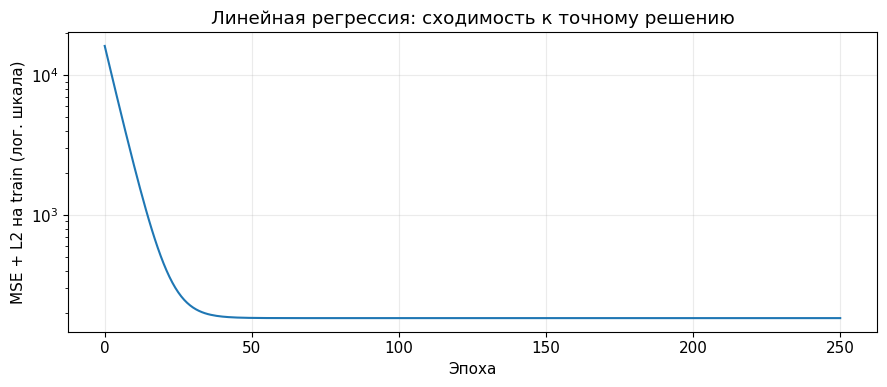

Градиенты, отсутствие штрафа для bias, SGD с batch_size=1 и повторный fit проверены.


In [10]:
test_rng = np.random.default_rng(12)
X_grad = test_rng.normal(size=(13, 4))
gradient_checks = []
for kind in ['lin_reg', 'log_reg']:
    y_grad = test_rng.normal(size=13) if kind == 'lin_reg' else test_rng.integers(0, 2, 13)
    for C in [0.1, 1, 10]:
        tested = MySGDClassifier(batch_generator, C=C, model_type=kind)
        tested.weights = test_rng.normal(size=5)
        analytic = tested.calc_loss_grad(X_grad, y_grad)
        numeric = np.zeros(5)
        eps = 1e-6
        for j in range(5):
            old = tested.weights[j]
            tested.weights[j] = old + eps
            plus = tested.calc_loss(X_grad, y_grad)
            tested.weights[j] = old - eps
            minus = tested.calc_loss(X_grad, y_grad)
            tested.weights[j] = old
            numeric[j] = (plus - minus) / (2 * eps)
        np.testing.assert_allclose(analytic, numeric, atol=1e-7, rtol=1e-6)
        gradient_checks.append((kind, C, np.max(np.abs(analytic - numeric))))
display(pd.DataFrame(gradient_checks, columns=['Модель', 'C', 'Макс. ошибка градиента']))
np.testing.assert_allclose(sigmoid([-1000, 0, 1000]), [0, 0.5, 1])

# Изменение C не должно менять компоненту градиента по bias.
tested.C = 0.01
bias_grad_1 = tested.calc_loss_grad(X_grad, y_grad)[0]
tested.C = 100
assert tested.calc_loss_grad(X_grad, y_grad)[0] == bias_grad_1

X_reg, y_reg = make_regression(n_samples=600, n_features=6, noise=5,
                              bias=20, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
reg_scaler = StandardScaler().fit(Xr_train)
Xr_train, Xr_test = reg_scaler.transform(Xr_train), reg_scaler.transform(Xr_test)
lin_model = MySGDClassifier(batch_generator, C=100, alpha=0.05, max_epoch=250,
                            batch_size=len(yr_train), shuffle=False, model_type='lin_reg')
lin_model.fit(Xr_train, yr_train)
design = np.column_stack((np.ones(len(yr_train)), Xr_train))
penalty = np.diag(np.r_[0, np.ones(Xr_train.shape[1])]) / lin_model.C
exact_weights = np.linalg.solve(design.T @ design / len(yr_train) + penalty,
                                 design.T @ yr_train / len(yr_train))
np.testing.assert_allclose(lin_model.weights, exact_weights, atol=1e-5)
display(pd.DataFrame({
    'Решение': ['MySGDClassifier: lin_reg', 'Точное решение L2'],
    'Test MSE': [mean_squared_error(yr_test, lin_model.predict(Xr_test)),
                 mean_squared_error(yr_test, np.column_stack((np.ones(len(yr_test)), Xr_test)) @ exact_weights)],
}))
print(f'Test R² = {r2_score(yr_test, lin_model.predict(Xr_test)):.6f}')
print(f'Максимальная разница весов = {np.max(np.abs(lin_model.weights - exact_weights)):.3e}')
plt.plot(lin_model.epoch_log_['epoch'], lin_model.epoch_log_['loss'])
plt.yscale('log')
plt.xlabel('Эпоха')
plt.ylabel('MSE + L2 на train (лог. шкала)')
plt.title('Линейная регрессия: сходимость к точному решению')
plt.tight_layout()
plt.show()

# Размер батча 1, отсутствие перемешивания, повторный fit и непрерывный predict.
small = MySGDClassifier(batch_generator, max_epoch=2, batch_size=1, shuffle=False)
small.fit(Xr_train[:7], yr_train[:7])
old_weights = small.weights.copy()
assert small.n_iter_ == 14 and small.predict(Xr_test[:2]).dtype.kind == 'f'
small.fit(Xr_train[:7], yr_train[:7])
np.testing.assert_allclose(small.weights, old_weights)
assert len(small.errors_log['iter']) == 14
print('Градиенты, отсутствие штрафа для bias, SGD с batch_size=1 и повторный fit проверены.')

### Задание 4 (2 балла)


Обучите свою логистическую регрессию и визуализируйте график ошибок по эпохам и по итерациям (step/шагам)
Посчитайте метрики на тестовой выборке

Train: (800, 10) Test: (200, 10)
Масштабирование обучено только на train.


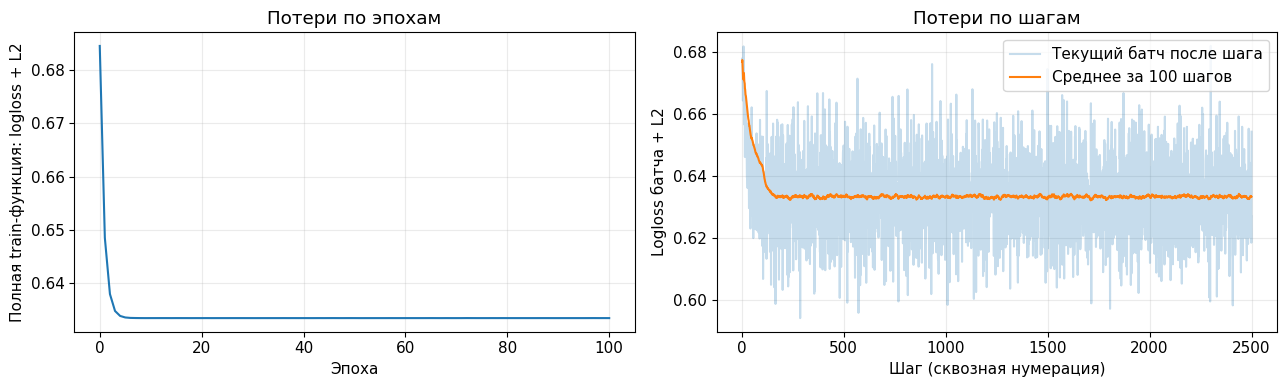

,Своя реализация,sklearn,Разница
Метрика,,,
accuracy,0.930000,0.930000,0.0
recall,0.910000,0.910000,0.0
precision,0.947917,0.947917,0.0
F1,0.928571,0.928571,0.0
ROC-AUC,0.982700,0.982700,0.0


**Вывод.** За 100 эпох train-функция уменьшилась с 0.684450 до 0.633514. На тесте accuracy = 0.9300, F1 = 0.9286, ROC-AUC = 0.9827. На графике отдельных шагов остаётся шум: батчи меняются, а шаг постоянен. Это само по себе не означает расходимость; полная функция на train выходит на плато.

Минимум полной функции (BFGS): 0.63351116; отклонение SGD: 0.00000238


In [11]:
X, y = make_classification(n_samples=1000, n_features=10,
                           n_informative=2, n_redundant=1,
                           random_state=123, class_sep=1.0, flip_y=0,
                           n_clusters_per_class=2)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y)
scaler = StandardScaler().fit(X_train_raw)
X_train, X_test = scaler.transform(X_train_raw), scaler.transform(X_test_raw)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Масштабирование обучено только на train.')

model = MySGDClassifier(batch_generator, max_epoch=100, model_type='log_reg',
                        C=1, alpha=0.01, batch_size=32, random_state=42)
model.fit(X_train, y_train)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(model.epoch_log_['epoch'], model.epoch_log_['loss'])
axes[0].set(xlabel='Эпоха', ylabel='Полная train-функция: logloss + L2', title='Потери по эпохам')
steps = np.array(model.errors_log['iter'])
step_losses = pd.Series(model.errors_log['loss'])
axes[1].plot(steps, step_losses, alpha=0.25, label='Текущий батч после шага')
axes[1].plot(steps, step_losses.rolling(100, min_periods=1).mean(), label='Среднее за 100 шагов')
axes[1].set(xlabel='Шаг (сквозная нумерация)', ylabel='Logloss батча + L2', title='Потери по шагам')
axes[1].legend()
fig.tight_layout()
plt.show()

test_pred, test_scores = model.predict(X_test), model.predict_proba(X_test)[:, 1]
test_metrics = metric_comparison(y_test, test_pred, test_scores)
display(test_metrics)
display(Markdown(
    f"**Вывод.** За 100 эпох train-функция уменьшилась с {model.epoch_log_['loss'][0]:.6f} "
    f"до {model.epoch_log_['loss'][-1]:.6f}. На тесте accuracy = {my_accuracy_score(y_test, test_pred):.4f}, "
    f"F1 = {my_f1_score(y_test, test_pred):.4f}, ROC-AUC = {my_roc_auc_score(y_test, test_scores):.4f}. "
    'На графике отдельных шагов остаётся шум: батчи меняются, а шаг постоянен. '
    'Это само по себе не означает расходимость; полная функция на train выходит на плато.'))

# Независимая проверка логистической оптимизации через scipy, без обучения sklearn внутри класса.
reference = MySGDClassifier(batch_generator, C=1, model_type='log_reg')
def objective(weights):
    reference.weights = weights
    return reference.calc_loss(X_train, y_train), reference.calc_loss_grad(X_train, y_train)
opt = minimize(objective, np.zeros(X_train.shape[1] + 1), jac=True, method='BFGS',
               options={'gtol': 1e-8, 'maxiter': 1000})
assert np.linalg.norm(opt.jac, ord=np.inf) < 1e-6
gap = model.calc_loss(X_train, y_train) - opt.fun
assert -1e-10 <= gap < 0.002
print(f'Минимум полной функции (BFGS): {opt.fun:.8f}; отклонение SGD: {gap:.8f}')

Выведите полученные веса и нарисуйте разделяющую границу между классами (используйте только первых два веса для первых двух признаков X[:,0], X[:,1] для отображения в 2d пространство ).  

,Коэффициент,Значение
0,bias,0.000504
1,"w для X[:, 0]",0.005825
2,"w для X[:, 1]",0.180073
3,"w для X[:, 2]",0.005651
4,"w для X[:, 3]",-0.129945
5,"w для X[:, 4]",-0.005082
6,"w для X[:, 5]",0.000922
7,"w для X[:, 6]",0.002825
8,"w для X[:, 7]",0.005266
9,"w для X[:, 8]",-0.002495


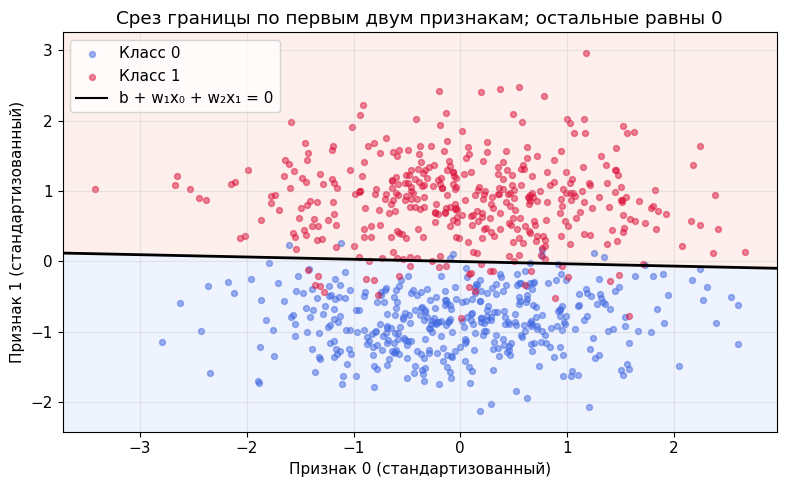

In [12]:
def plot_decision_boundary(clf):
    # Срез в стандартизованном пространстве: x2,...,x9 = 0 (средние train).
    x0 = np.linspace(X_train[:, 0].min() - 0.3, X_train[:, 0].max() + 0.3, 200)
    x1 = np.linspace(X_train[:, 1].min() - 0.3, X_train[:, 1].max() + 0.3, 200)
    xx, yy = np.meshgrid(x0, x1)
    zz = clf.weights[0] + clf.weights[1] * xx + clf.weights[2] * yy
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.contourf(xx, yy, zz >= 0, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.15)
    for label, color in [(0, 'royalblue'), (1, 'crimson')]:
        mask = y_train == label
        ax.scatter(X_train[mask, 0], X_train[mask, 1], c=color, s=18,
                   alpha=0.5, label=f'Класс {label}')
    if zz.min() < 0 < zz.max():
        ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=2)
        ax.plot([], [], color='black', label='b + w₁x₀ + w₂x₁ = 0')
    ax.set(xlabel='Признак 0 (стандартизованный)', ylabel='Признак 1 (стандартизованный)',
           title='Срез границы по первым двум признакам; остальные равны 0')
    ax.legend()
    fig.tight_layout()
    plt.show()


display(pd.DataFrame({'Коэффициент': ['bias'] + [f'w для X[:, {j}]' for j in range(10)],
                       'Значение': model.weights}))
plot_decision_boundary(model)

**Как читать границу.** Модель обучалась на всех 10 признаках. Чёрная линия —
срез её гиперплоскости при нулевых значениях остальных восьми стандартизованных
признаков. На рисунке сами объекты спроецированы на первые два признака,
поэтому их расположение относительно линии не определяет предсказание полной модели.

Далее будем анализировать Ваш алгоритм.
Для этих заданий используйте датасет ниже.

In [13]:
X_large, y_large = make_classification(n_samples=100000, n_features=10,
                                      n_informative=4, n_redundant=0,
                                      random_state=123, class_sep=1.0,
                                      n_clusters_per_class=1)
Xl_train_raw, Xl_valid_raw, yl_train, yl_valid = train_test_split(
    X_large, y_large, test_size=0.2, random_state=42, stratify=y_large)
large_scaler = StandardScaler().fit(Xl_train_raw)
Xl_train = large_scaler.transform(Xl_train_raw)
Xl_valid = large_scaler.transform(Xl_valid_raw)
print('Большой датасет:', X_large.shape, '; train:', Xl_train.shape, '; validation:', Xl_valid.shape)

Большой датасет: (100000, 10) ; train: (80000, 10) ; validation: (20000, 10)


Покажите сходимости на этом датасете: изобразите график  функции потерь, по эпохам шагам градиентого спуска, для разных `alpha` (размеров шага). Разные `alpha` расположите на одном графике.

max epoch можно брать 10, 50, 100 и т.д.

,alpha,Начальная функция,Конечная функция,Минимум по эпохам,Размах за последние 5 эпох,Validation ROC-AUC
0,0.0001,0.682929,0.628278,0.628278,2.181293e-03,0.990046
1,0.0010,0.682929,0.622152,0.622152,4.264537e-08,0.991321
2,0.0100,0.682929,0.622155,0.622153,1.736558e-06,0.991268
3,0.1000,0.682929,0.622329,0.622202,2.334883e-04,0.990512
4,0.7000,0.682929,0.629649,0.623035,9.453974e-03,0.977840


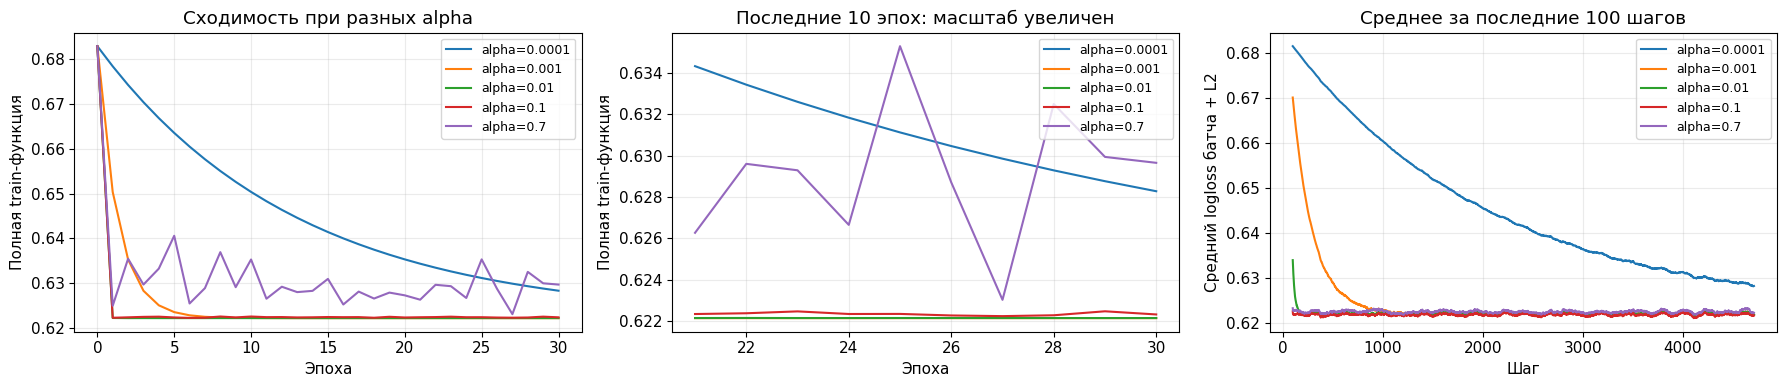

**Вывод о сходимости.** Все модели получили одинаковую инициализацию, порядок батчей, C=1 и 30 эпох. При alpha=0.0001 начальное снижение медленнее. Больший шаг ускоряет первые изменения, но усиливает остаточные колебания около минимума. Минимальная конечная train-функция в этом запуске получена при **alpha=0.001**: 0.622152. Для сходимости в данном эксперименте выбираем это значение; это не универсально лучший шаг для других масштабов признаков, C или размеров батча. Потери текущих разных батчей напрямую не сравнимы, поэтому основной график показывает одну и ту же полную train-функцию после каждой эпохи.

In [14]:
alphas = [0.0001, 0.001, 0.01, 0.1, 0.7]
alpha_models, alpha_rows = {}, []
for alpha in alphas:
    fitted = MySGDClassifier(batch_generator, C=1, alpha=alpha, max_epoch=30,
                             model_type='log_reg', batch_size=512, random_state=42)
    fitted.fit(Xl_train, yl_train)
    alpha_models[alpha] = fitted
    history = np.array(fitted.epoch_log_['loss'])
    alpha_rows.append((alpha, history[0], history[-1], history[1:].min(),
                       np.ptp(history[-5:]), my_roc_auc_score(yl_valid, fitted.predict_proba(Xl_valid)[:, 1])))
alpha_table = pd.DataFrame(alpha_rows, columns=[
    'alpha', 'Начальная функция', 'Конечная функция', 'Минимум по эпохам',
    'Размах за последние 5 эпох', 'Validation ROC-AUC'])
display(alpha_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for alpha, fitted in alpha_models.items():
    epochs = fitted.epoch_log_['epoch']
    loss = fitted.epoch_log_['loss']
    label = f'alpha={alpha:g}'
    axes[0].plot(epochs, loss, label=label)
    axes[1].plot(epochs[-10:], loss[-10:], label=label)
    smoothed = pd.Series(fitted.errors_log['loss']).rolling(100, min_periods=100).mean()
    axes[2].plot(fitted.errors_log['iter'], smoothed, label=label)
axes[0].set(xlabel='Эпоха', ylabel='Полная train-функция', title='Сходимость при разных alpha')
axes[1].set(xlabel='Эпоха', ylabel='Полная train-функция', title='Последние 10 эпох: масштаб увеличен')
axes[2].set(xlabel='Шаг', ylabel='Средний logloss батча + L2', title='Среднее за последние 100 шагов')
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

best_alpha = float(alpha_table.loc[alpha_table['Конечная функция'].idxmin(), 'alpha'])
display(Markdown(
    '**Вывод о сходимости.** Все модели получили одинаковую инициализацию, порядок батчей, '
    'C=1 и 30 эпох. При alpha=0.0001 начальное снижение медленнее. Больший шаг ускоряет '
    'первые изменения, но усиливает остаточные колебания около минимума. '
    f'Минимальная конечная train-функция в этом запуске получена при **alpha={best_alpha:g}**: '
    f"{alpha_table['Конечная функция'].min():.6f}. "
    'Для сходимости в данном эксперименте выбираем это значение; это не универсально '
    'лучший шаг для других масштабов признаков, C или размеров батча. '
    'Потери текущих разных батчей напрямую не сравнимы, поэтому основной график '
    'показывает одну и ту же полную train-функцию после каждой эпохи.'))

Что Вы можете сказать про сходимость метода при различных `alpha`? Какое значение стоит выбирать для лучшей сходимости?

Изобразите график среднего значения весов в зависимости от коеф. регуляризации С из `np.logspace(3, -3, 10)`

Для исследования регуляризации возьмём ровно `np.logspace(3, -3, 10)`.
Чтобы отделить силу штрафа от случайного шума и недообучения, используем
полный батч и проверяем норму градиента. Это частный случай реализованного
mini-batch GD. Здесь задача — сравнить сошедшиеся веса, а не скорость SGD.

При малых C постоянный шаг 0.01 становится слишком большим: только штраф
имеет кривизну $2/C$. Поэтому для каждого C берём шаг $0.9/L_C$, где
$L_C=\lambda_{max}(\widetilde X^T\widetilde X/n)/4+2/C$ — верхняя оценка
гладкости логистической функции, а $\widetilde X=[1,X]$.

,C,alpha,Среднее w,Среднее |w|,L2-норма w,bias,Норма градиента (inf),Validation ROC-AUC
0,1000.000000,1.638931,-0.342568,0.860234,4.366745,0.613013,8.588953e-09,0.994996
1,215.443469,1.617479,-0.230774,0.617946,3.168273,0.401855,2.359224e-16,0.994929
2,46.415888,1.524837,-0.133516,0.388400,2.021477,0.194677,5.551115e-17,0.994755
3,10.000000,1.204596,-0.063989,0.203459,1.083821,0.055926,2.775558e-17,0.994208
4,2.154435,0.609981,-0.023419,0.078885,0.435367,0.006042,2.775558e-17,0.992512
5,0.464159,0.185337,-0.006386,0.021826,0.123849,0.000554,1.084202e-19,0.990388
6,0.100000,0.043802,-0.001471,0.005038,0.028861,0.000402,1.096793e-08,0.989493
7,0.021544,0.009638,-0.000322,0.001105,0.006331,0.000637,5.929498e-05,0.989266
8,0.004642,0.002086,-0.000070,0.000239,0.001369,0.001971,3.927995e-04,0.989217
9,0.001000,0.000450,-0.000015,0.000052,0.000295,0.002766,5.913903e-04,0.989207


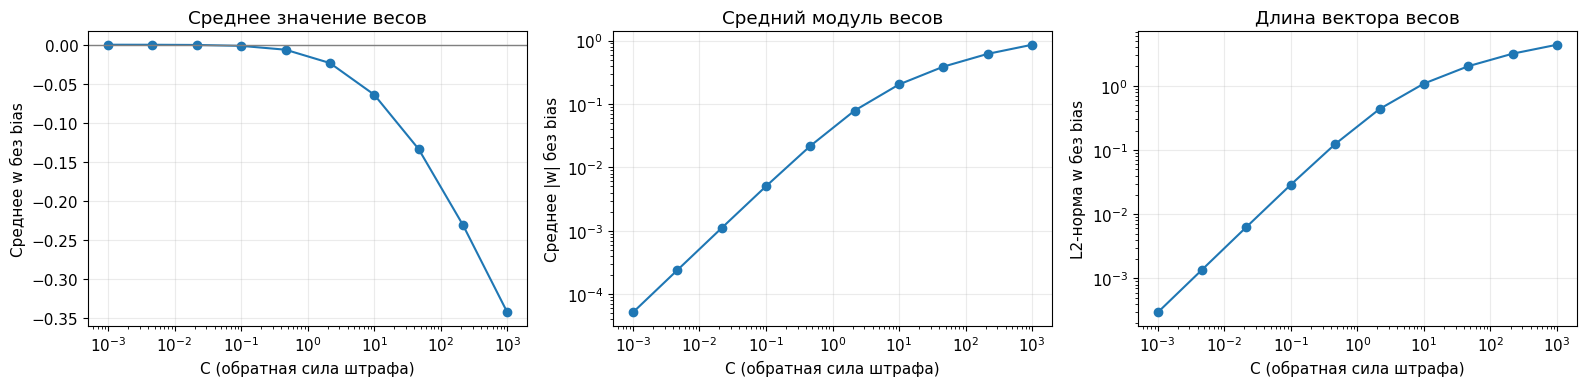

**Вывод.** При уменьшении C с 1000 до 0.001 средний модуль весов уменьшился с 0.860234 до 0.000052, то есть в **16683.3 раза**. L2-норма уменьшилась с 4.366745 до 0.000295. Это ожидаемое действие L2: усиление штрафа сжимает коэффициенты. Обычное среднее знаковых весов может быть близко к нулю из-за взаимной компенсации, поэтому дополнительно показаны средний модуль и норма. Свободный коэффициент исключён из штрафа и из этих статистик. Сжатие достаточно сильное, но само по себе не означает улучшения качества: validation ROC-AUC меняется с 0.994996 до 0.989207. C следует выбирать по валидации. Сходимость контролируется нормой градиента в таблице; у самых малых C она может быть ограничена более медленной настройкой свободного коэффициента.

In [15]:
C_values = np.logspace(3, -3, 10)
augmented = np.column_stack((np.ones(len(yl_train)), Xl_train))
logistic_curvature = np.linalg.eigvalsh(augmented.T @ augmented / len(yl_train)).max() / 4
regularization_models, regularization_rows = {}, []
for C in C_values:
    alpha_C = 0.9 / (logistic_curvature + 2 / C)
    fitted = MySGDClassifier(batch_generator, C=float(C), alpha=alpha_C,
                             max_epoch=1000, model_type='log_reg',
                             batch_size=len(yl_train), shuffle=False, random_state=42)
    fitted.fit(Xl_train, yl_train)
    w = fitted.weights[1:]  # bias исключён из всех статистик весов
    grad_inf = np.linalg.norm(fitted.calc_loss_grad(Xl_train, yl_train), ord=np.inf)
    regularization_models[C] = fitted
    regularization_rows.append((C, alpha_C, w.mean(), np.abs(w).mean(), np.linalg.norm(w),
                                fitted.weights[0], grad_inf,
                                my_roc_auc_score(yl_valid, fitted.predict_proba(Xl_valid)[:, 1])))
regularization_table = pd.DataFrame(regularization_rows, columns=[
    'C', 'alpha', 'Среднее w', 'Среднее |w|', 'L2-норма w', 'bias',
    'Норма градиента (inf)', 'Validation ROC-AUC'])
display(regularization_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ordered = regularization_table.sort_values('C')
axes[0].semilogx(ordered['C'], ordered['Среднее w'], 'o-')
axes[0].axhline(0, color='gray', linewidth=1)
axes[0].set(xlabel='C (обратная сила штрафа)', ylabel='Среднее w без bias', title='Среднее значение весов')
axes[1].loglog(ordered['C'], ordered['Среднее |w|'], 'o-')
axes[1].set(xlabel='C (обратная сила штрафа)', ylabel='Среднее |w| без bias', title='Средний модуль весов')
axes[2].loglog(ordered['C'], ordered['L2-норма w'], 'o-')
axes[2].set(xlabel='C (обратная сила штрафа)', ylabel='L2-норма w без bias', title='Длина вектора весов')
fig.tight_layout()
plt.show()

strong = regularization_table.iloc[-1]
weak = regularization_table.iloc[0]
shrinkage = weak['Среднее |w|'] / strong['Среднее |w|']
assert (regularization_table['Норма градиента (inf)'] < 0.002).all()
assert np.all(np.diff(regularization_table['L2-норма w']) <= 1e-7)
display(Markdown(
    f"**Вывод.** При уменьшении C с 1000 до 0.001 средний модуль весов уменьшился "
    f"с {weak['Среднее |w|']:.6f} до {strong['Среднее |w|']:.6f}, то есть в **{shrinkage:.1f} раза**. "
    f"L2-норма уменьшилась с {weak['L2-норма w']:.6f} до {strong['L2-норма w']:.6f}. "
    'Это ожидаемое действие L2: усиление штрафа сжимает коэффициенты. '
    'Обычное среднее знаковых весов может быть близко к нулю из-за взаимной компенсации, '
    'поэтому дополнительно показаны средний модуль и норма. '
    'Свободный коэффициент исключён из штрафа и из этих статистик. '
    'Сжатие достаточно сильное, но само по себе не означает улучшения качества: '
    f"validation ROC-AUC меняется с {weak['Validation ROC-AUC']:.6f} "
    f"до {strong['Validation ROC-AUC']:.6f}. C следует выбирать по валидации. "
    'Сходимость контролируется нормой градиента в таблице; у самых малых C она '
    'может быть ограничена более медленной настройкой свободного коэффициента.'))

### Итог

Все пять метрик проверены по sklearn. KNN использует евклидово расстояние;
сравнение точности и повторные измерения времени приведены выше. Обе модели
обучаются реализованным градиентным спуском, причём bias не регуляризуется.
Градиенты проверены численно, линейная регрессия — по точному решению,
логистическая — по независимому минимуму функции потерь.

Построены графики потерь по эпохам и шагам, срез разделяющей границы, сравнение
разных alpha и зависимость весов от всех заданных C. Масштабирование обучается
только на train; результаты экспериментов и конкретные выводы сохранены в выводах ячеек.